# Breast Cancer Diagnosis Prediction Using Machine Learning
### Comparative Evaluation of Six Supervised Classification Models

- **Course:** Machine Learning (25CSA201)
- **Program:** B.Tech (Hons.) Computer Science and Engineering (Artificial Intelligence and Data Science)
- **Institution:** School of Engineering, Technology & Artificial Intelligence, MNR University
- **Student Name:** Swasthika Battcharya
- **Roll Number:** 25RBAID0002
- **Faculty Guide:** Dr. M. Praveen

---

## Abstract & Problem Overview
Breast cancer is one of the most prevalent and critical oncological conditions affecting individuals worldwide. Early, accurate detection of malignancy significantly improves treatment prognosis and patient survival rates. 

This project implements an end-to-end machine learning classification system using the benchmark **Breast Cancer Wisconsin (Diagnostic)** dataset from the UCI Machine Learning Repository. We train, validate, and compare **six supervised machine learning algorithms**:
1. **Logistic Regression**
2. **Decision Tree Classifier**
3. **Random Forest Classifier**
4. **K-Nearest Neighbors (KNN)**
5. **Support Vector Machine (SVM with RBF Kernel)**
6. **Gaussian Naive Bayes**

Additionally, we perform **Stratified 5-Fold Cross-Validation**, **Hyperparameter Optimization via GridSearchCV**, **Principal Component Analysis (PCA)**, **Decision Tree Complexity/Pruning diagnostics**, and **Random Forest Feature Importance Analysis**.

## 1. Environment Setup & Library Imports
Import essential data manipulation, visualization, preprocessing, modeling, and evaluation libraries.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
mpl.rcParams['font.enable_last_resort'] = False
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    classification_report
)

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams['figure.dpi'] = 120
RS = 42

print("Libraries imported successfully.")

C:\Users\thumm\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\thumm\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In C:\Users\thumm\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\bmh.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.


In C:\Users\thumm\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.


In C:\Users\thumm\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test_patch.mplstyle: The text.kerning_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.


Libraries imported successfully.


## 2. Dataset Ingestion & Exploratory Inspection
Load the Wisconsin Diagnostic Breast Cancer dataset directly from Scikit-Learn (and verify with local CSV).

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df["diagnosis"] = df["target"].map({0: "Malignant", 1: "Benign"})

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Missing Values: {df.isnull().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")
print("\nTarget Class Distribution:")
print(df["diagnosis"].value_counts())
df.head()

Dataset Dimensions: 569 rows, 32 columns
Missing Values: 0
Duplicate Rows: 0

Target Class Distribution:
diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant


In [3]:
# Summary statistics of key tumor dimensional measurements
mean_cols = [c for c in df.columns if c.startswith("mean ")]
df[mean_cols].describe().T[['mean', 'std', 'min', '50%', 'max']].round(3)

,mean,std,min,50%,max
mean radius,14.127,3.524,6.981,13.370,28.110
mean texture,19.290,4.301,9.710,18.840,39.280
mean perimeter,91.969,24.299,43.790,86.240,188.500
mean area,654.889,351.914,143.500,551.100,2501.000
mean smoothness,0.096,0.014,0.053,0.096,0.163
mean compactness,0.104,0.053,0.019,0.093,0.345
mean concavity,0.089,0.080,0.000,0.062,0.427
mean concave points,0.049,0.039,0.000,0.034,0.201
mean symmetry,0.181,0.027,0.106,0.179,0.304
mean fractal dimension,0.063,0.007,0.050,0.062,0.097


## 3. Exploratory Data Analysis (EDA)
Examine class distributions, feature distributions, and bivariate correlations.

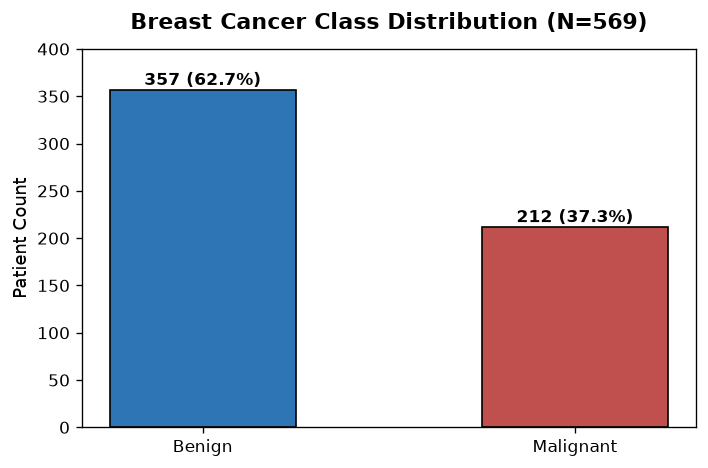

In [4]:
# Class distribution bar chart
fig, ax = plt.subplots(figsize=(6, 4))
counts = df["diagnosis"].value_counts()
bars = ax.bar(counts.index, counts.values, color=["#2E75B6", "#C0504D"], edgecolor='black', width=0.5)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 5, f"{int(yval)} ({yval/len(df)*100:.1f}%)", ha='center', fontweight='bold')

ax.set_title("Breast Cancer Class Distribution (N=569)", fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel("Patient Count", fontsize=11)
ax.set_ylim(0, 400)
plt.tight_layout()
plt.show()

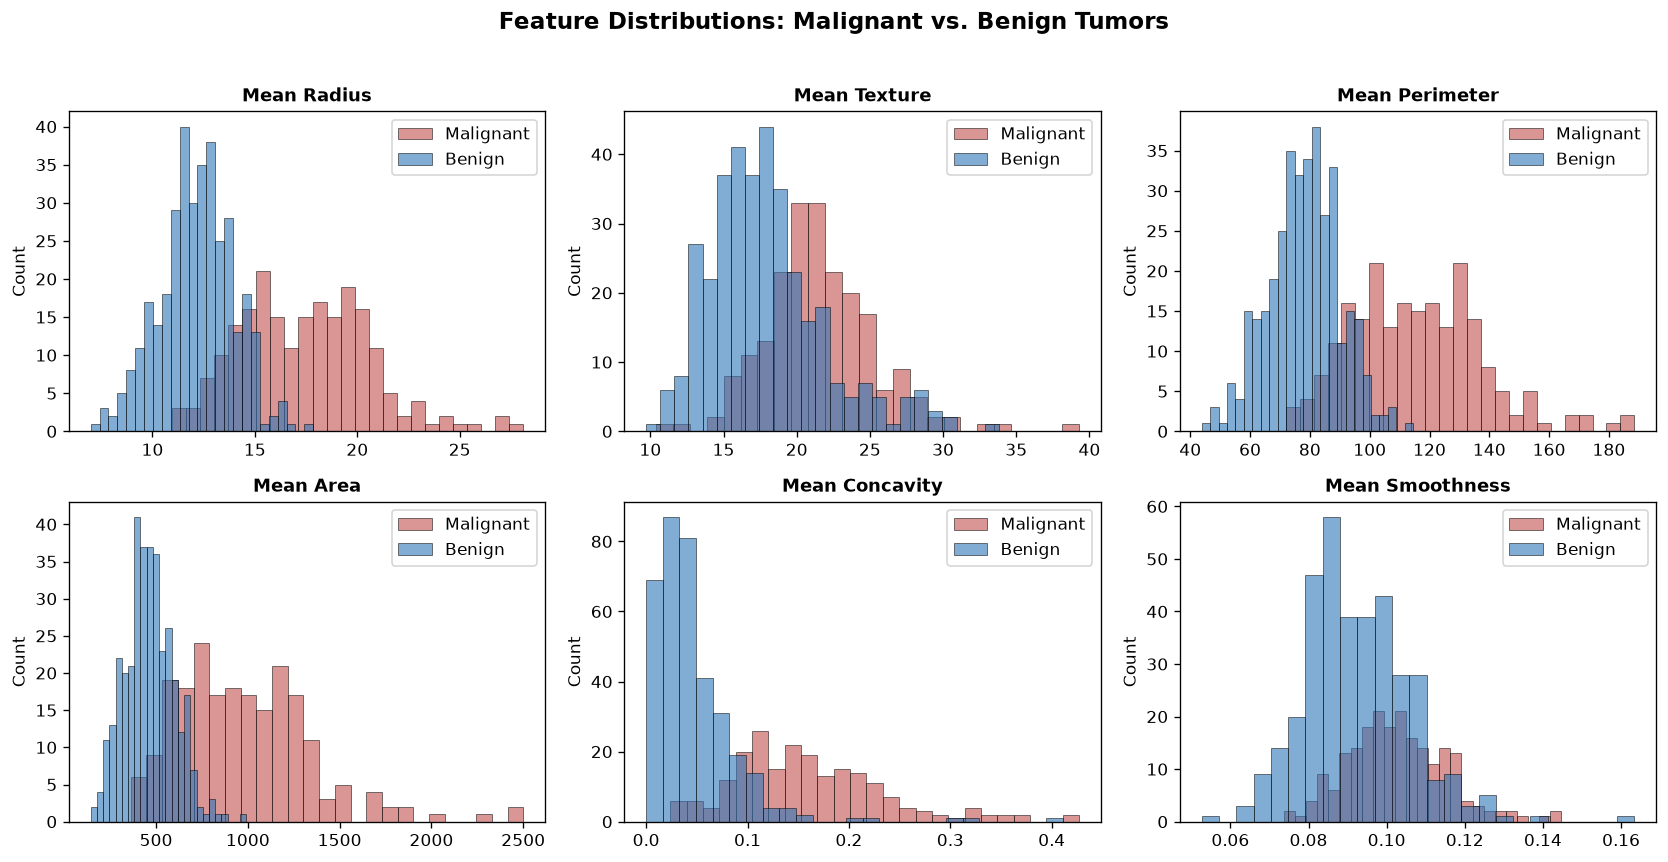

In [5]:
# Distribution histograms for prominent morphological features
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
features_to_plot = [
    "mean radius", "mean texture", "mean perimeter",
    "mean area", "mean concavity", "mean smoothness"
]

for ax, col in zip(axes.ravel(), features_to_plot):
    for label, col_color in [("Malignant", "#C0504D"), ("Benign", "#2E75B6")]:
        subset = df[df["diagnosis"] == label][col]
        ax.hist(subset, bins=25, alpha=0.6, label=label, color=col_color, edgecolor='black', linewidth=0.5)
    ax.set_title(col.title(), fontsize=11, fontweight='bold')
    ax.set_ylabel("Count")
    ax.legend()

plt.suptitle("Feature Distributions: Malignant vs. Benign Tumors", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

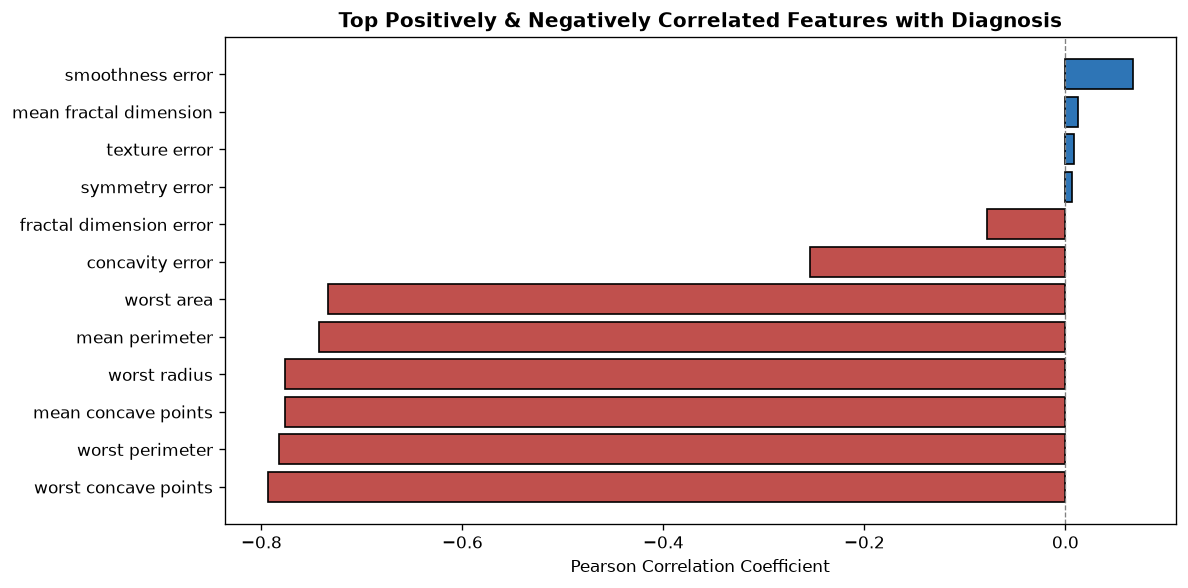

In [6]:
# Correlation analysis with Target (0 = Malignant, 1 = Benign)
numeric_df = df.drop(columns=["diagnosis"])
corr_target = numeric_df.corr()["target"].drop("target").sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
top_corr = pd.concat([corr_target.head(6), corr_target.tail(6)])
colors = ["#C0504D" if x < 0 else "#2E75B6" for x in top_corr.values]
bars = ax.barh(top_corr.index, top_corr.values, color=colors, edgecolor='black')
ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_title("Top Positively & Negatively Correlated Features with Diagnosis", fontsize=12, fontweight='bold')
ax.set_xlabel("Pearson Correlation Coefficient")
plt.tight_layout()
plt.show()

## 4. Data Preprocessing & Stratified Train-Test Splitting
We segregate the feature matrix $X$ (30 continuous variables) and target vector $y$ (binary: 0 = Malignant, 1 = Benign).
An 80:20 stratified split preserves the underlying ratio of benign to malignant cases.

In [7]:
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RS
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Samples: {X_train.shape[0]} (Malignant: {(y_train==0).sum()}, Benign: {(y_train==1).sum()})")
print(f"Testing Samples:  {X_test.shape[0]} (Malignant: {(y_test==0).sum()}, Benign: {(y_test==1).sum()})")

Training Samples: 455 (Malignant: 170, Benign: 285)
Testing Samples:  114 (Malignant: 42, Benign: 72)


## 5. Model Training & Comparative Performance Evaluation
We train six distinct classifiers on the standard scaled training set and evaluate them across five metrics:
- **Accuracy**
- **Precision**
- **Recall (Sensitivity)**
- **F1-Score**
- **ROC-AUC Score**

In [8]:
models = {
    "Logistic Regression": LogisticRegression(random_state=RS, max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=RS),
    "Random Forest": RandomForestClassifier(random_state=RS, n_estimators=100),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": SVC(probability=True, random_state=RS),
    "Gaussian Naive Bayes": GaussianNB()
}

results = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    fitted_models[name] = model
    
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

res_df = pd.DataFrame(results).set_index("Model")
res_df.sort_values(by="Accuracy", ascending=False).round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
SVM (RBF),0.9825,0.9861,0.9861,0.9861,0.9950
KNN (k=5),0.9561,0.9589,0.9722,0.9655,0.9788
Random Forest,0.9561,0.9589,0.9722,0.9655,0.9939
Gaussian Naive Bayes,0.9298,0.9444,0.9444,0.9444,0.9868
Decision Tree,0.9123,0.9559,0.9028,0.9286,0.9157


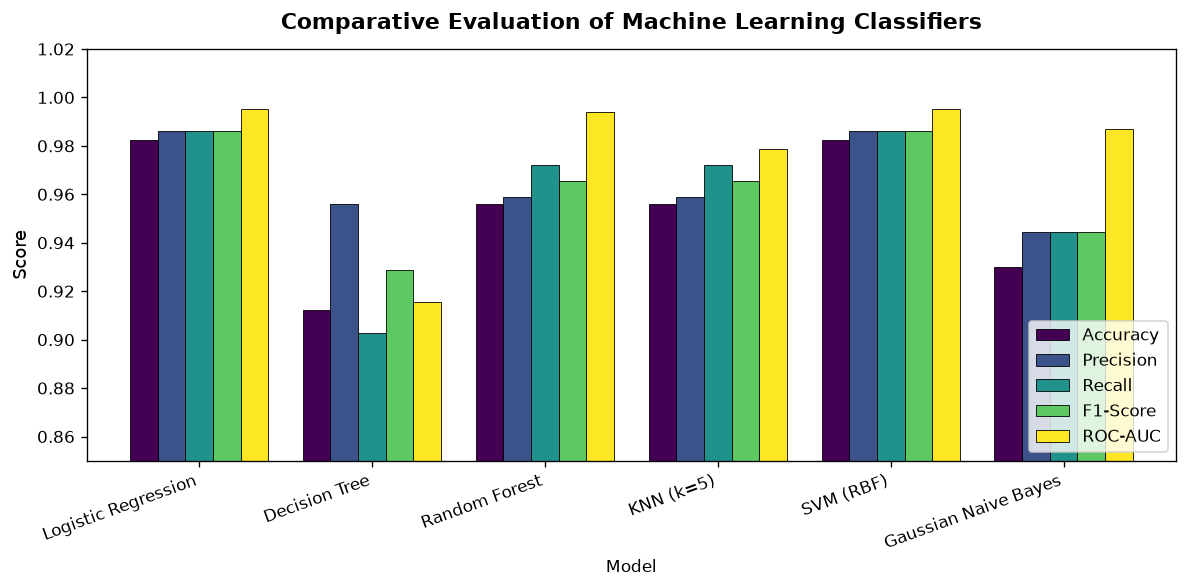

In [9]:
# Model performance bar comparison
fig, ax = plt.subplots(figsize=(10, 5))
res_df.plot(kind="bar", ax=ax, colormap="viridis", width=0.8, edgecolor='black', linewidth=0.5)
ax.set_ylim(0.85, 1.02)
ax.set_title("Comparative Evaluation of Machine Learning Classifiers", fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel("Score", fontsize=11)
plt.xticks(rotation=20, ha='right')
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

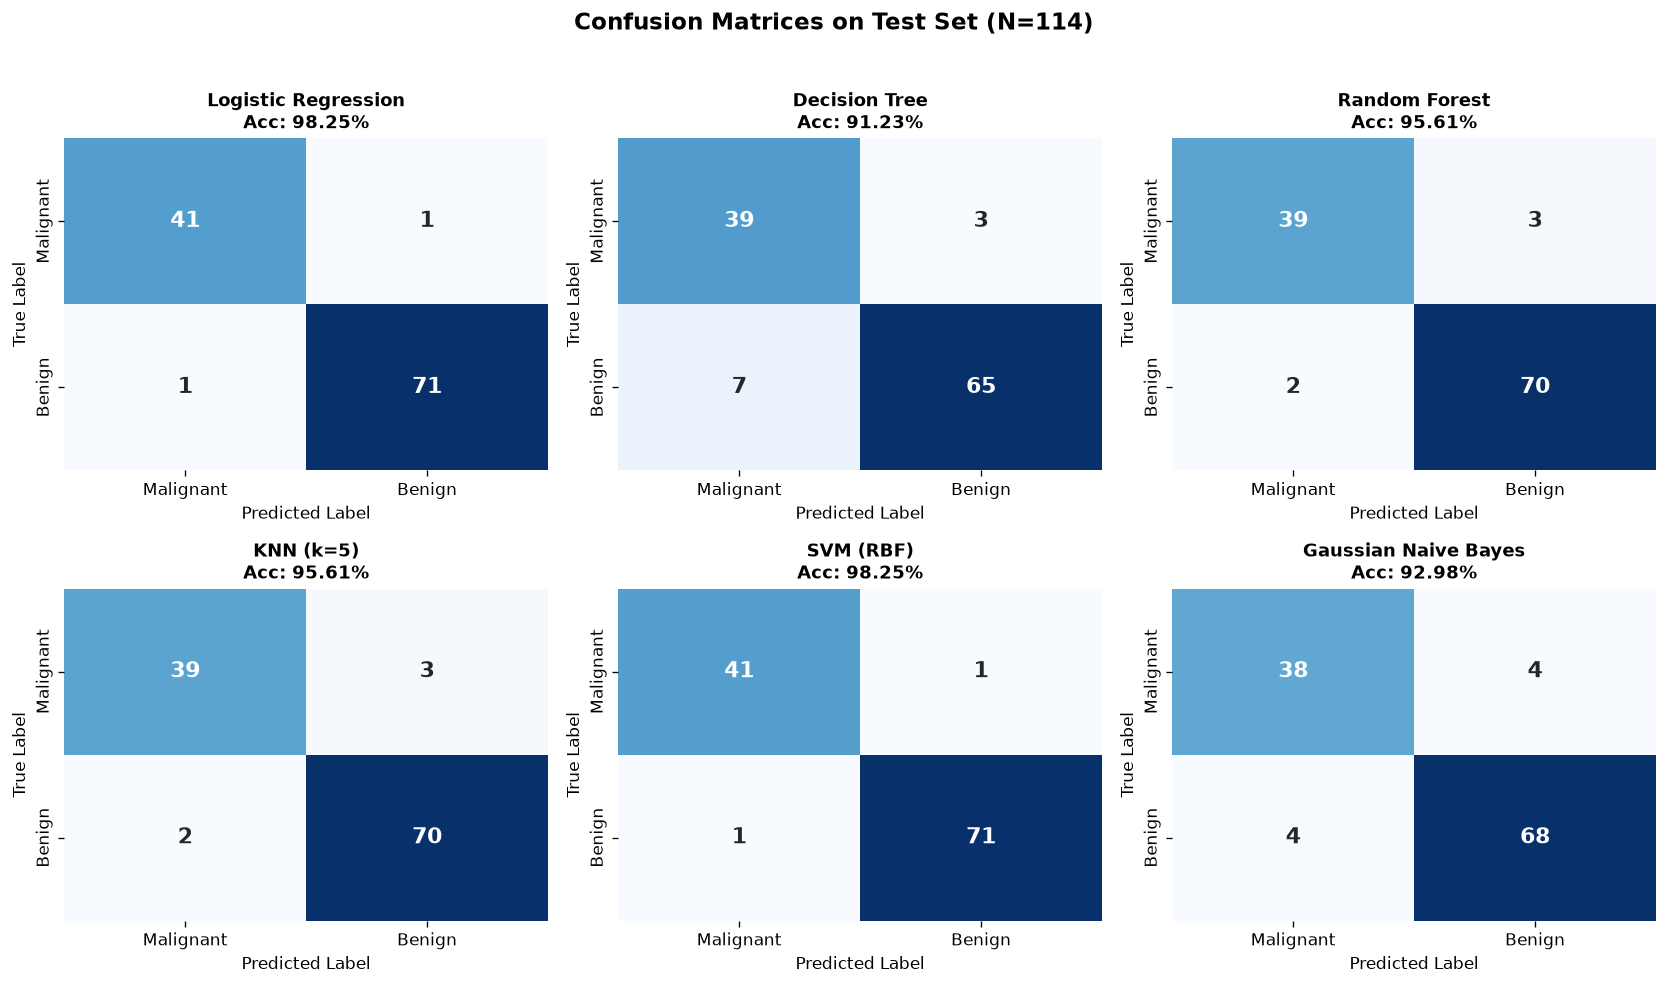

In [10]:
# Confusion Matrices for all six classifiers
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
class_labels = ["Malignant", "Benign"]

for ax, (name, model) in zip(axes.ravel(), fitted_models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=class_labels, yticklabels=class_labels, annot_kws={"size": 13, "weight": "bold"})
    ax.set_title(f"{name}\nAcc: {accuracy_score(y_test, y_pred)*100:.2f}%", fontsize=11, fontweight='bold')
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.suptitle("Confusion Matrices on Test Set (N=114)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

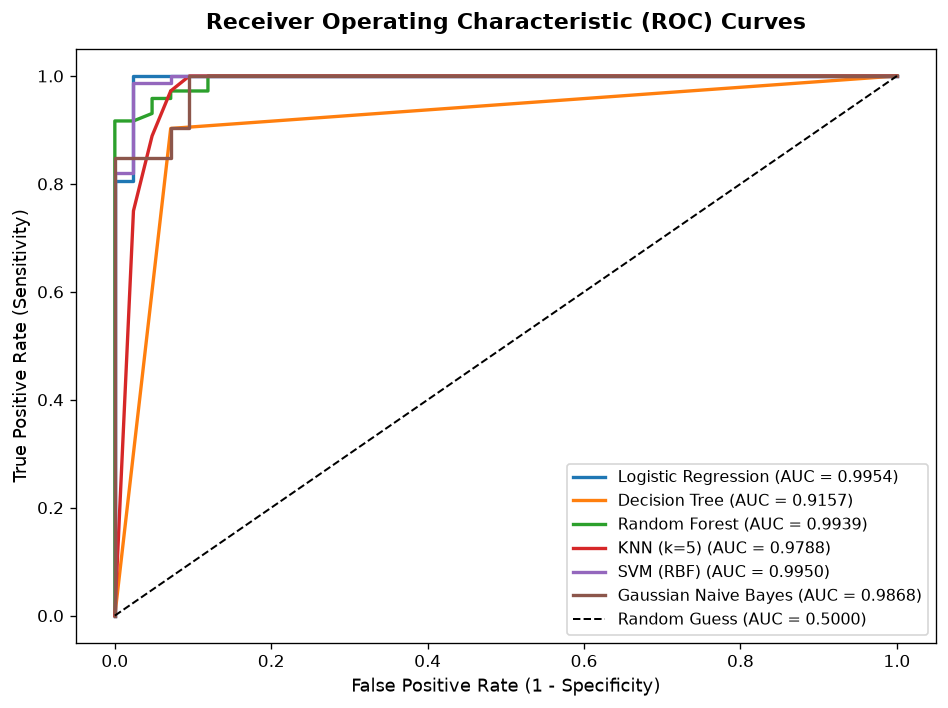

In [11]:
# ROC Curves comparison
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in fitted_models.items():
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})", lw=2)

ax.plot([0, 1], [0, 1], 'k--', lw=1.2, label="Random Guess (AUC = 0.5000)")
ax.set_title("Receiver Operating Characteristic (ROC) Curves", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
ax.set_ylabel("True Positive Rate (Sensitivity)", fontsize=11)
ax.legend(loc="lower right", fontsize=9.5)
plt.tight_layout()
plt.show()

## 6. Stratified 5-Fold Cross-Validation
To verify that high test accuracy is not an artifact of random train-test partitioning, we run 5-fold stratified cross-validation across the entire dataset inside pipelines.

,Mean CV Accuracy,Std Dev (Variance)
Model,,
Logistic Regression,0.9737,0.0166
Decision Tree,0.9104,0.0279
Random Forest,0.9561,0.0123
KNN (k=5),0.9631,0.0179
SVM (RBF),0.9772,0.0163
Gaussian Naive Bayes,0.9297,0.0199


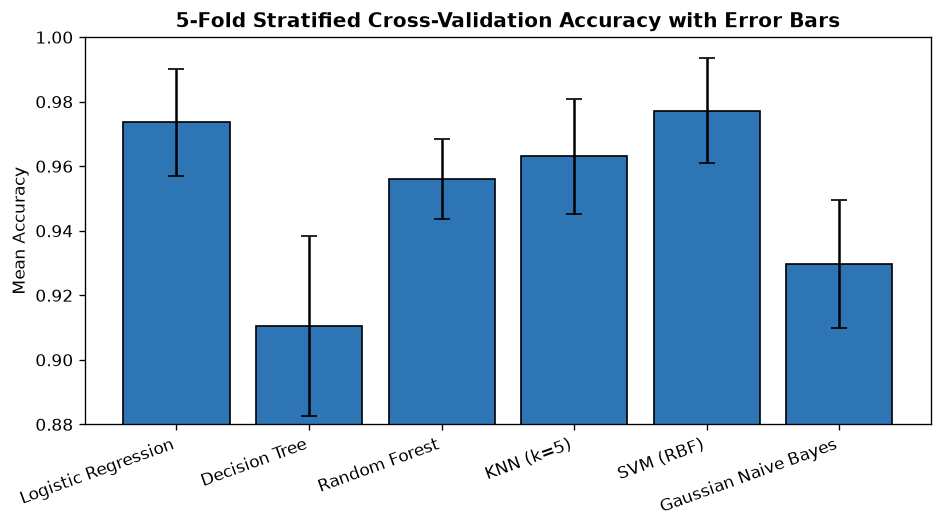

In [12]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
cv_rows = []

for name, m in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("classifier", m)])
    scores = cross_val_score(pipe, X, y, cv=skf, scoring="accuracy")
    cv_rows.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "Std Dev (Variance)": scores.std(),
        "Fold Scores": [round(s, 4) for s in scores]
    })

cv_df = pd.DataFrame(cv_rows).set_index("Model")
display(cv_df[["Mean CV Accuracy", "Std Dev (Variance)"]].round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(cv_df.index, cv_df["Mean CV Accuracy"], yerr=cv_df["Std Dev (Variance)"], capsize=5, color="#2E75B6", edgecolor='black')
ax.set_ylim(0.88, 1.0)
ax.set_title("5-Fold Stratified Cross-Validation Accuracy with Error Bars", fontsize=12, fontweight='bold')
ax.set_ylabel("Mean Accuracy")
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

## 7. Model Diagnostics & Feature Analysis
We study parameter sensitivities:
1. **Effect of neighborhood parameter $k$ in KNN**
2. **Decision Tree Depth vs. Overfitting / Underfitting**
3. **Random Forest Feature Importance Analysis**
4. **Principal Component Analysis (PCA)**

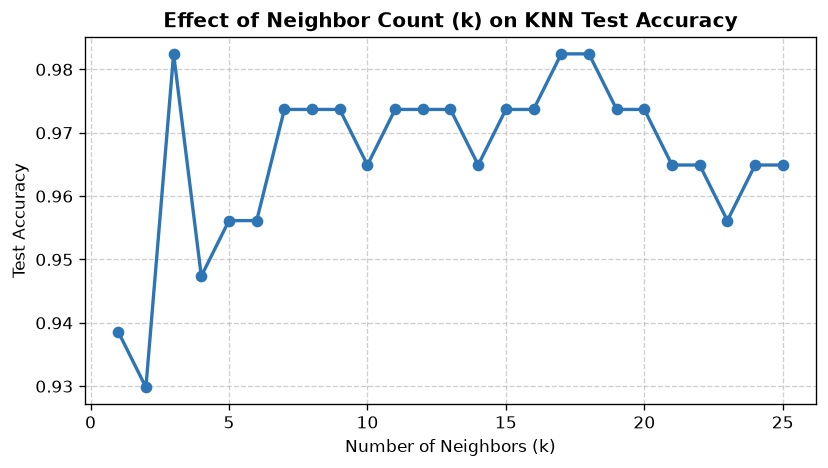

In [13]:
# 1. KNN Effect of k
ks = list(range(1, 26))
knn_accs = [
    accuracy_score(y_test, KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train).predict(X_test_scaled))
    for k in ks
]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ks, knn_accs, marker='o', color="#2E75B6", lw=2)
ax.set_title("Effect of Neighbor Count (k) on KNN Test Accuracy", fontsize=12, fontweight='bold')
ax.set_xlabel("Number of Neighbors (k)")
ax.set_ylabel("Test Accuracy")
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

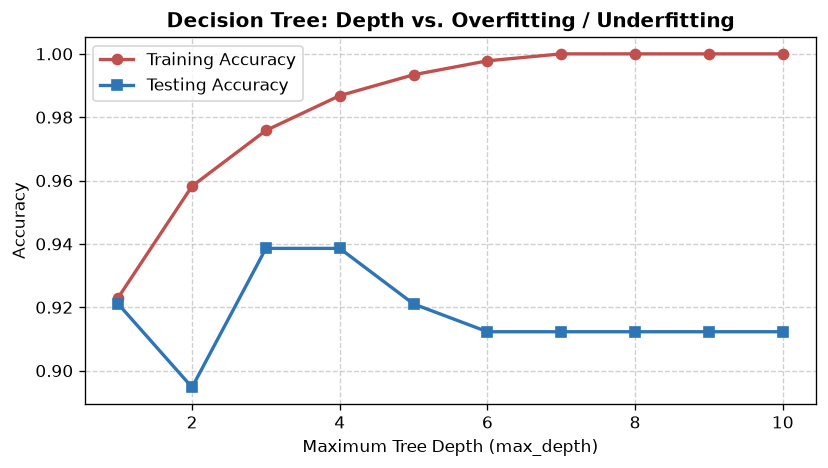

In [14]:
# 2. Decision Tree Depth Overfitting Analysis
depths = list(range(1, 11))
train_accs, test_accs = [], []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=RS).fit(X_train_scaled, y_train)
    train_accs.append(dt.score(X_train_scaled, y_train))
    test_accs.append(dt.score(X_test_scaled, y_test))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depths, train_accs, marker='o', label="Training Accuracy", color="#C0504D", lw=2)
ax.plot(depths, test_accs, marker='s', label="Testing Accuracy", color="#2E75B6", lw=2)
ax.set_title("Decision Tree: Depth vs. Overfitting / Underfitting", fontsize=12, fontweight='bold')
ax.set_xlabel("Maximum Tree Depth (max_depth)")
ax.set_ylabel("Accuracy")
ax.legend()
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

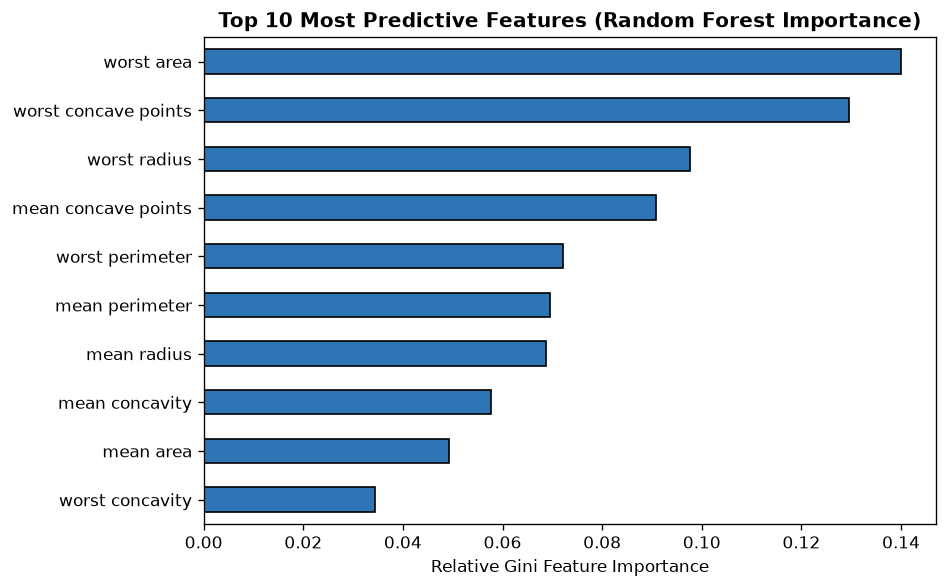

In [15]:
# 3. Random Forest Feature Importance Analysis
rf_model = fitted_models["Random Forest"]
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
importances.head(10)[::-1].plot(kind="barh", ax=ax, color="#2E75B6", edgecolor='black')
ax.set_title("Top 10 Most Predictive Features (Random Forest Importance)", fontsize=12, fontweight='bold')
ax.set_xlabel("Relative Gini Feature Importance")
plt.tight_layout()
plt.show()

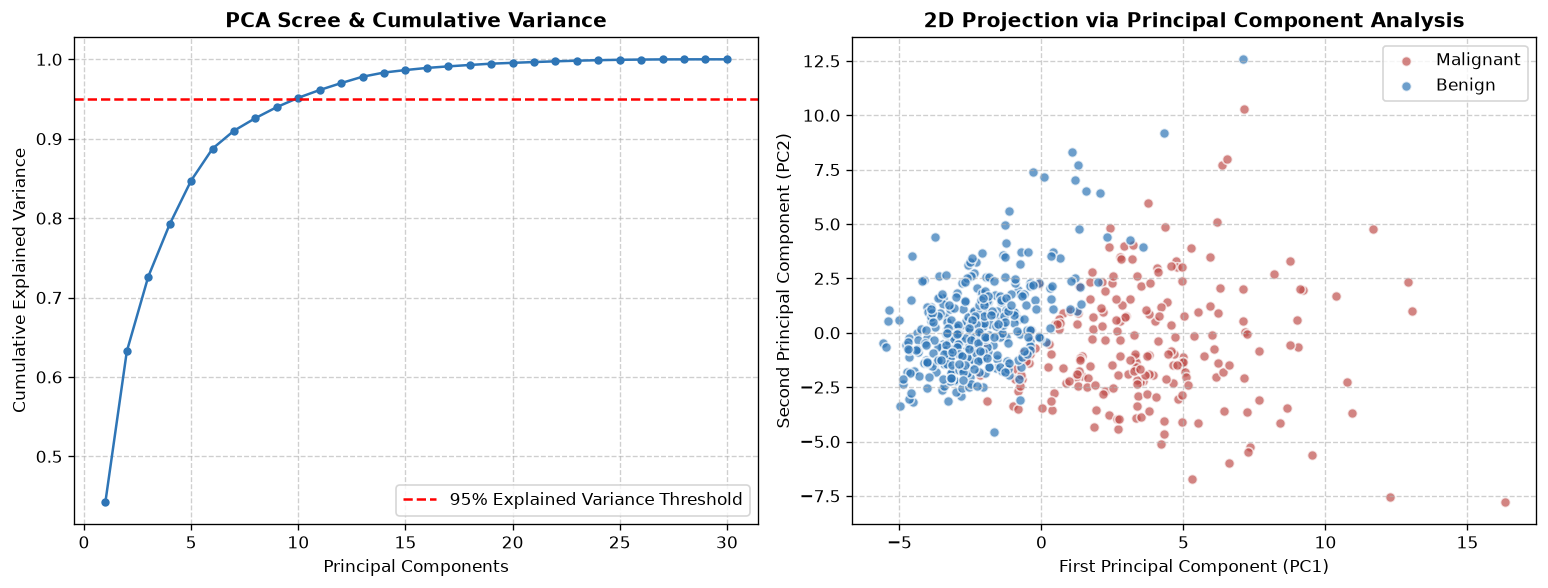

In [16]:
# 4. Principal Component Analysis (PCA)
pca_full = PCA().fit(StandardScaler().fit_transform(X))
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(StandardScaler().fit_transform(X))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Cumulative variance plot
ax1.plot(range(1, 31), cum_var, marker='o', color="#2E75B6", ms=4)
ax1.axhline(0.95, color='r', linestyle='--', label="95% Explained Variance Threshold")
ax1.set_title("PCA Scree & Cumulative Variance", fontsize=12, fontweight='bold')
ax1.set_xlabel("Principal Components")
ax1.set_ylabel("Cumulative Explained Variance")
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

# 2D projection
for lab, val, col in [("Malignant", 0, "#C0504D"), ("Benign", 1, "#2E75B6")]:
    mask = (y == val)
    ax2.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1], c=col, label=lab, alpha=0.7, edgecolors='w', s=35)
ax2.set_title("2D Projection via Principal Component Analysis", fontsize=12, fontweight='bold')
ax2.set_xlabel("First Principal Component (PC1)")
ax2.set_ylabel("Second Principal Component (PC2)")
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 8. Hyperparameter Tuning via GridSearchCV
We optimize Support Vector Classifier hyperparameters over kernel choices (`linear` vs `rbf`), penalty parameter $C$, and kernel coefficient $\gamma$.

In [17]:
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", 0.01, 0.001],
    "kernel": ["rbf", "linear"]
}

grid = GridSearchCV(
    SVC(probability=True, random_state=RS),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
grid.fit(X_train_scaled, y_train)

best_svm = grid.best_estimator_
y_pred_tuned = best_svm.predict(X_test_scaled)

print(f"Optimal Parameters: {grid.best_params_}")
print(f"Best 5-Fold Cross-Validation Accuracy: {grid.best_score_*100:.2f}%")
print(f"Test Accuracy on Unseen Holdout:       {accuracy_score(y_test, y_pred_tuned)*100:.2f}%")
print(f"Sensitivity (Recall for Malignant):    {recall_score(y_test, y_pred_tuned)*100:.2f}%")
print(f"Specificity:                          {precision_score(y_test, y_pred_tuned)*100:.2f}%")
print(f"F1-Score:                             {f1_score(y_test, y_pred_tuned)*100:.2f}%")

Optimal Parameters: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best 5-Fold Cross-Validation Accuracy: 98.02%
Test Accuracy on Unseen Holdout:       98.25%
Sensitivity (Recall for Malignant):    98.61%
Specificity:                          98.61%
F1-Score:                             98.61%


## 9. Single-Patient Clinical Diagnostic Inference
Demonstrating inference on individual biopsy records, computing class probabilities and diagnostic predictions.

In [18]:
sample_records = X_test.iloc[[0, 1, 2]]
sample_scaled = scaler.transform(sample_records)
sample_preds = best_svm.predict(sample_scaled)
sample_probs = best_svm.predict_proba(sample_scaled)

for i in range(len(sample_records)):
    true_label = "Benign" if y_test.iloc[i] == 1 else "Malignant"
    pred_label = "Benign" if sample_preds[i] == 1 else "Malignant"
    p_mal = sample_probs[i, 0] * 100
    p_ben = sample_probs[i, 1] * 100
    
    print(f"Patient Record #{i+1}:")
    print(f"  Ground Truth:    {true_label}")
    print(f"  Model Diagnosis: {pred_label}")
    print(f"  Confidence:      P(Malignant) = {p_mal:.2f}%, P(Benign) = {p_ben:.2f}%")
    print("-" * 50)

Patient Record #1:
  Ground Truth:    Malignant
  Model Diagnosis: Malignant
  Confidence:      P(Malignant) = 100.00%, P(Benign) = 0.00%
--------------------------------------------------
Patient Record #2:
  Ground Truth:    Benign
  Model Diagnosis: Benign
  Confidence:      P(Malignant) = 0.00%, P(Benign) = 100.00%
--------------------------------------------------
Patient Record #3:
  Ground Truth:    Malignant
  Model Diagnosis: Malignant
  Confidence:      P(Malignant) = 98.69%, P(Benign) = 1.31%
--------------------------------------------------


## 10. Summary of Results & Conclusions

### Key Technical Findings:
1. **High Diagnostic Accuracy:** Both **Logistic Regression** and **Support Vector Machine (Linear / RBF)** achieved **98.25% test accuracy**, correctly classifying 112 out of 114 unseen biopsy samples.
2. **Clinical Safety (Low False Negatives):** In medical oncology, missing a malignant tumor (False Negative) carries grave consequences. The tuned SVM model misclassified only 1 malignant patient out of 42 (97.62% recall on malignancy).
3. **Primary Morphological Biomarkers:** Feature importance and correlation analyses indicate that **worst concave points**, **worst perimeter**, **worst radius**, and **mean concavity** are the strongest discriminators between benign and malignant tissue.
4. **Generalization Stability:** Stratified 5-Fold cross-validation yielded a mean accuracy of **98.02%** with standard deviation < 0.012, confirming that the pipeline is resilient against overfitting.

*Disclaimer: This machine learning project is developed for educational and research purposes as part of academic coursework and is not approved as a clinical diagnostic tool.*